# Model comparison and chosen models

**Deliverables 4 and 5:** the model comparison table on the validation set, and for each chosen model the test-set
median and 95th-percentile error, a predicted-vs-SPICE plot and the saved model file.

| Section | Content |
|---|---|
| 1. Model comparison (validation set) | every model type × case: R², median and 95th-percentile error (plus mean) |
| 2. Chosen models | the model chosen for each case, why, and its saved file |
| 3. Test-set results | the chosen models on the test set, computed here from the saved files |
| 4. Predicted vs SPICE | one parity plot per case (test set) |
| 5. Where the mean error comes from | how few rows cause the large mean errors, and why (test set) |

**How it works**
- The comparison table is read from the result files `validation_comparison_*.csv` in this folder: written by the
  training notebooks (five model types), by `ML_Models/Scripts/export_huber_models.py` (the MLP with the Huber loss) and by
  `ML_Models/Scripts/train_on_models_gate_region.py` (the ON models trained with extra gate-region rows).
- The chosen models are **loaded from `ML_Models/Saved_Models/`** with `ML_Models/Scripts/leakage_model.py` and evaluated
  here. The test set is used **only in this notebook**.
- Each device type has its own training notebook (`pmos_models.ipynb`, `nmos_models.ipynb`); a case whose
  notebook has not been run yet is listed as missing.

**Files written:** `test_results.csv` and `error_concentration.csv` (this folder) and `parity_<case>.png` (`ML_Models/Plots/`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "Data_Generation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the DVD-Project repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "ML_Models" / "Scripts"))
from leakage_model import LeakageModel, OUTPUT_COLS, error_table, split_indices

DATA_DIR    = ROOT / "Data_Generation" / "Datasets"
RESULTS_DIR = ROOT / "ML_Models" / "Results"
MODEL_DIR   = ROOT / "ML_Models" / "Saved_Models"
PLOT_DIR    = ROOT / "ML_Models" / "Plots"
CASES = ["NMOS_ON", "NMOS_OFF", "PMOS_ON", "PMOS_OFF"]
MODEL_ORDER = ["Random forest", "XGBoost", "Polynomial (Ridge)", "MLP", "MLP + Kirchhoff loss", "MLP (Huber loss)",
               "MLP (Huber loss) + gate-region data"]
METRICS = ["R2 (log|I|)", "median err %", "95th pct err %", "mean err %"]

pd.set_option("display.float_format", lambda v: f"{v:.3g}")
BLUE, LIGHT_BLUE = "#2a78d6", "#9ec5f4"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9, "legend.frameon": False,
})

## 1. Model comparison table — validation set

- **R²** on log10|I|
- **% error** = |I_pred / I_SPICE − 1| × 100, summarized by its **median**, **95th percentile** and **mean**
- Each value is the **average over the four currents** (id, ig, is, ib); the per-current values follow below.
- Rows are the four model types, plus two variants of the MLP: with the Kirchhoff (physics-informed) loss term, and with a
  Huber loss instead of MSE (same network and data, trained in the follow-up study: `ML_Models/Scripts/run_offstudy.py --stage 13`);
  for all four cases also the Huber MLP trained with 4,000 extra rows from the gate operating region
  (`train_on_models_gate_region.py`; validated on the same 2,000 validation rows).

In [2]:
files = sorted(RESULTS_DIR.glob("validation_comparison_*.csv"))
comparison = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("result files:", ", ".join(f.name for f in files))
missing = [c for c in CASES if c not in set(comparison["case"])]
print("cases without results yet:", ", ".join(missing) if missing else "none")

avg = comparison[comparison["current"] == "average"]
table = avg.pivot_table(index="model", columns="case", values=METRICS)
table = table.swaplevel(axis=1)                                       # columns: (case, metric)
table = table.reindex(columns=[(c, m) for c in CASES for m in METRICS if (c, m) in table.columns])
table = table.reindex([m for m in MODEL_ORDER if m in table.index])
table

result files: validation_comparison_GATE_REGION.csv, validation_comparison_HUBER.csv, validation_comparison_NMOS.csv, validation_comparison_PMOS.csv
cases without results yet: none


case                                    NMOS_ON                              \
                                    R2 (log|I|) median err % 95th pct err %   
model                                                                         
Random forest                             0.988         14.3           56.1   
XGBoost                                   0.999         3.14           14.4   
Polynomial (Ridge)                        0.996         5.79             28   
MLP                                           1        0.239            1.3   
MLP + Kirchhoff loss                          1        0.595           3.16   
MLP (Huber loss)                              1        0.102          0.664   
MLP (Huber loss) + gate-region data           1        0.149          0.842   

case                                              NMOS_OFF               \
                                    mean err % R2 (log|I|) median err %   
model                                                                     
Random forest                             23.4        0.92         10.2   
XGBoost                                   5.55       0.982         3.45   
Polynomial (Ridge)                         9.2       0.869         13.7   
MLP                                      0.543       0.976        0.397   
MLP + Kirchhoff loss                      1.34        0.99        0.408   
MLP (Huber loss)                         0.571       0.992        0.119   
MLP (Huber loss) + gate-region data      0.513       0.994        0.226   

case                                                              PMOS_ON  \
                                    95th pct err % mean err % R2 (log|I|)   
model                                                                       
Random forest                                 47.5        201       0.988   
XGBoost                                       20.7       69.1       0.999   
Polynomial (Ridge)                              67        244       0.997   
MLP                                           2.96       8.52           1   
MLP + Kirchhoff loss                          2.83       7.25           1   
MLP (Huber loss)                              1.02       4.71           1   
MLP (Huber loss) + gate-region data           1.88       4.13           1   

case                                                                        \
                                    median err % 95th pct err % mean err %   
model                                                                        
Random forest                               14.2           54.4       20.3   
XGBoost                                     2.86           12.6       4.37   
Polynomial (Ridge)                          4.46           22.1       7.02   
MLP                                        0.345           1.62      0.559   
MLP + Kirchhoff loss                       0.426           2.15      0.761   
MLP (Huber loss)                          0.0942          0.623      0.221   
MLP (Huber loss) + gate-region data        0.147          0.843      0.306   

case                                   PMOS_OFF                              \
                                    R2 (log|I|) median err % 95th pct err %   
model                                                                         
Random forest                             0.923         9.75           49.8   
XGBoost                                   0.985         3.33           19.4   
Polynomial (Ridge)                        0.868         14.6           77.3   
MLP                                        0.99         0.33           2.02   
MLP + Kirchhoff loss                      0.991        0.346           2.25   
MLP (Huber loss)                          0.995        0.124          0.859   
MLP (Huber loss) + gate-region data       0.996        0.146           1.19   

case                                            
                                    mean err %  
model            

In [3]:
# per current: median and 95th-percentile error on the validation set
per_current = comparison[comparison["current"] != "average"].pivot_table(
    index=["case", "model"], columns="current", values=["median err %", "95th pct err %"])
per_current = per_current.swaplevel(axis=1)
per_current = per_current.reindex(columns=[(c, m) for c in OUTPUT_COLS for m in ["median err %", "95th pct err %"]])
per_current.reindex([(c, m) for c in CASES for m in MODEL_ORDER if (c, m) in per_current.index])

current                                                id                 \
                                             median err % 95th pct err %   
case     model                                                             
NMOS_ON  Random forest                               10.7           47.9   
         XGBoost                                     2.14           14.5   
         Polynomial (Ridge)                          4.37           19.8   
         MLP                                        0.206           1.09   
         MLP + Kirchhoff loss                        0.51           2.26   
         MLP (Huber loss)                          0.0849           0.44   
         MLP (Huber loss) + gate-region data        0.142          0.723   
NMOS_OFF Random forest                               12.5           54.3   
         XGBoost                                     5.18             37   
         Polynomial (Ridge)                          24.7            134   
         MLP                                        0.562           4.14   
         MLP + Kirchhoff loss                       0.582           3.89   
         MLP (Huber loss)                           0.176           1.42   
         MLP (Huber loss) + gate-region data        0.282           2.45   
PMOS_ON  Random forest                               11.1           46.8   
         XGBoost                                     1.86           12.5   
         Polynomial (Ridge)                          4.01           13.3   
         MLP                                        0.339           1.33   
         MLP + Kirchhoff loss                       0.359           1.63   
         MLP (Huber loss)                          0.0716          0.399   
         MLP (Huber loss) + gate-region data        0.138          0.799   
PMOS_OFF Random forest                               11.9           55.6   
         XGBoost                                      5.1           33.4   
         Polynomial (Ridge)                          25.6            125   
         MLP                                        0.437           2.59   
         MLP + Kirchhoff loss                        0.47           2.75   
         MLP (Huber loss)                           0.156            1.2   
         MLP (Huber loss) + gate-region data        0.178            1.7   

current                                                ig                 \
                                             median err % 95th pct err %   
case     model                                                             
NMOS_ON  Random forest                               14.3           57.7   
         XGBoost                                     2.54           9.71   
         Polynomial (Ridge)                          9.76           48.5   
         MLP                                        0.233           1.71   
         MLP + Kirchhoff loss                       0.631           5.23   
         MLP (Huber loss)                           0.107           1.04   
         MLP (Huber loss) + gate-region data        0.146           1.16   
NMOS_OFF Random forest                               11.8           51.1   
         XGBoost                                     3.16           10.4   
         Polynomial (Ridge)                          2.06            8.9   
         MLP                                        0.382           2.22   
         MLP + Kirchhoff loss                       0.388           2.19   
         MLP (Huber loss)                           0.105          0.646   
         MLP (Huber loss) + gate-region data        0.244           1.57   
PMOS_ON  Random forest                               13.3           53.4   
         XGBoost                                     2.29           8.62   
         Polynomial (Ridge)                          5.25           45.6   
         MLP                                        0.267           1.85   
         MLP + Kirchhoff loss                  

## 2. Chosen models

**Rule:** for each case, the model with the lowest validation **median** and **95th-percentile** error (average over the four
currents), the metrics of deliverables 4 and 5. The MLP with the Huber loss is the best on both in all four cases. The final
model of every case is that MLP trained with 4,000 extra rows from the region where the transistor operates inside gates
(Part B): for the ON cases both terminals near one rail, |Vds| down to µV; for the OFF cases drain and source at opposite rails,
at the same rail, or one at a rail and one at a series-stack node. The extra rows cost 0.02 – 0.11 points of median error on the
uniformly sampled validation / test rows and removed most of the gate-level error. The training
notebooks first chose by the validation *mean*; section 5 shows that the mean is decided by a few near-cancelled rows, so it is
reported but not used for the choice. Each saved file is self-contained: network weights, hidden layers, feature list and
both scalers.

In [4]:
models, rows = {}, []
for case in CASES:
    path = MODEL_DIR / f"{case}.pt"
    if not path.exists():
        rows.append({"case": case, "model": "— not saved yet —"})
        continue
    m = LeakageModel(path)
    models[case] = m
    v = m.info["validation"]
    rows.append({"case": case, "model": m.info["model"], "hidden layers": "-".join(map(str, m.info["hidden"])),
                 "Kirchhoff λ": m.info.get("kirchhoff_lambda", 0.0),
                 "val median err %": v["median err %"], "val 95th pct err %": v["95th pct err %"], "val mean err %": v["mean err %"],
                 "file": str(path.relative_to(ROOT)), "size kB": path.stat().st_size / 1024})
pd.DataFrame(rows).set_index("case")

,model,hidden layers,Kirchhoff λ,val median err %,val 95th pct err %,val mean err %,file,size kB
case,,,,,,,,
NMOS_ON,MLP (Huber loss) + gate-region data,128-64-32-16,0,0.149,0.842,0.513,ML_Models/Saved_Models/NMOS_ON.pt,61.5
NMOS_OFF,MLP (Huber loss) + gate-region data,128-64-32-16,0,0.226,1.88,4.13,ML_Models/Saved_Models/NMOS_OFF.pt,61.6
PMOS_ON,MLP (Huber loss) + gate-region data,128-64-32-16,0,0.147,0.843,0.306,ML_Models/Saved_Models/PMOS_ON.pt,61.5
PMOS_OFF,MLP (Huber loss) + gate-region data,128-64-32-16,0,0.146,1.19,1.02,ML_Models/Saved_Models/PMOS_OFF.pt,61.6


## 3. Test-set results

The test set is the same 10 % (2,000 samples) as in training: the 80 / 10 / 10 split is rebuilt here from the dataset
with the same seed. It was not used for training or for choosing any setting.

First, a **reproduction check**: the validation error recomputed here from the saved file must equal the value recorded
when the model was trained, which proves that the file holds exactly the trained model.

In [5]:
test_tables, check, PRED = {}, [], {}
for case, m in models.items():
    df = pd.read_csv(DATA_DIR / m.info["dataset"])
    Y_log = np.log10(df[OUTPUT_COLS].abs()).values
    idx_train, idx_val, idx_test = split_indices(len(df), m.info.get("split_seed", m.info["seed"]))
    val = error_table(Y_log[idx_val], m.predict_log(df.iloc[idx_val])).loc["average"]
    check.append({"case": case, "val mean err % (recorded at training)": m.info["validation"]["mean err %"],
                  "val mean err % (recomputed from file)": val["mean err %"],
                  "match": bool(np.isclose(val["mean err %"], m.info["validation"]["mean err %"], rtol=1e-4))})
    pred_test = m.predict_log(df.iloc[idx_test])
    test_tables[case] = error_table(Y_log[idx_test], pred_test)
    PRED[case] = (Y_log[idx_test], pred_test)
pd.DataFrame(check).set_index("case")

,val mean err % (recorded at training),val mean err % (recomputed from file),match
case,,,
NMOS_ON,0.513,0.513,True
NMOS_OFF,4.13,4.13,True
PMOS_ON,0.306,0.306,True
PMOS_OFF,1.02,1.02,True


In [6]:
test_results = pd.concat(test_tables, names=["case", "current"])
test_results.to_csv(RESULTS_DIR / "test_results.csv")

# summary: chosen model per case, validation vs test (average over the four currents)
summary = pd.DataFrame({case: {"model": models[case].info["model"],
                               "val median err %": models[case].info["validation"]["median err %"],
                               "test median err %": t.loc["average", "median err %"],
                               "val 95th pct err %": models[case].info["validation"]["95th pct err %"],
                               "test 95th pct err %": t.loc["average", "95th pct err %"],
                               "test mean err %": t.loc["average", "mean err %"],
                               "test R2 (log|I|)": t.loc["average", "R2 (log|I|)"]}
                        for case, t in test_tables.items()}).T
display(summary)

# test set, per current
test_results

,model,val median err %,test median err %,val 95th pct err %,test 95th pct err %,test mean err %,test R2 (log|I|)
NMOS_ON,MLP (Huber loss) + gate-region data,0.149,0.145,0.842,0.82,0.548,1
NMOS_OFF,MLP (Huber loss) + gate-region data,0.226,0.238,1.88,1.94,3.57,0.988
PMOS_ON,MLP (Huber loss) + gate-region data,0.147,0.149,0.843,0.83,0.399,1
PMOS_OFF,MLP (Huber loss) + gate-region data,0.146,0.14,1.19,1.11,1.3,0.995


R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
NMOS_ON  id                 1       0.737          0.14           0.743
         ig                 1       0.397          0.14            1.11
         is             0.999       0.817         0.139           0.715
         ib                 1        0.24         0.162           0.718
         average            1       0.548         0.145            0.82
NMOS_OFF id             0.996        3.81         0.304            2.71
         ig                 1       0.537         0.249            1.53
         is             0.995        9.46          0.33            2.23
         ib             0.961       0.485        0.0699            1.29
         average        0.988        3.57         0.238            1.94
PMOS_ON  id             0.999       0.745         0.144           0.782
         ig                 1       0.272         0.131            0.98
         is                 1       0.302         0.142            0.74
         ib                 1       0.275         0.179           0.819
         average            1       0.399         0.149            0.83
PMOS_OFF id             0.996        3.48         0.171            1.48
         ig                 1       0.314         0.135           0.779
         is             0.999       0.907          0.18            1.42
         ib             0.987       0.518        0.0761           0.755
         average        0.995         1.3          0.14            1.11

## 4. Predicted vs SPICE — test set

Each point is one test sample; the dashed line is a perfect prediction. Axes are logarithmic because the currents
span many decades. Current magnitudes are shown; the signs come from `LeakageModel.predict_signed` (see `ML_Models/README.md`).

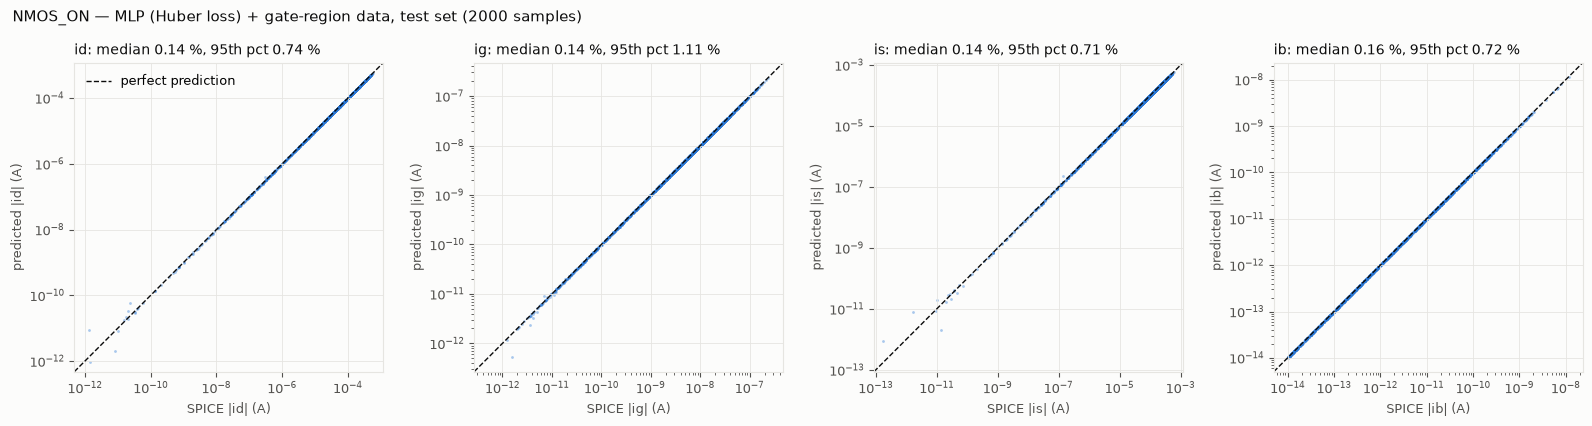

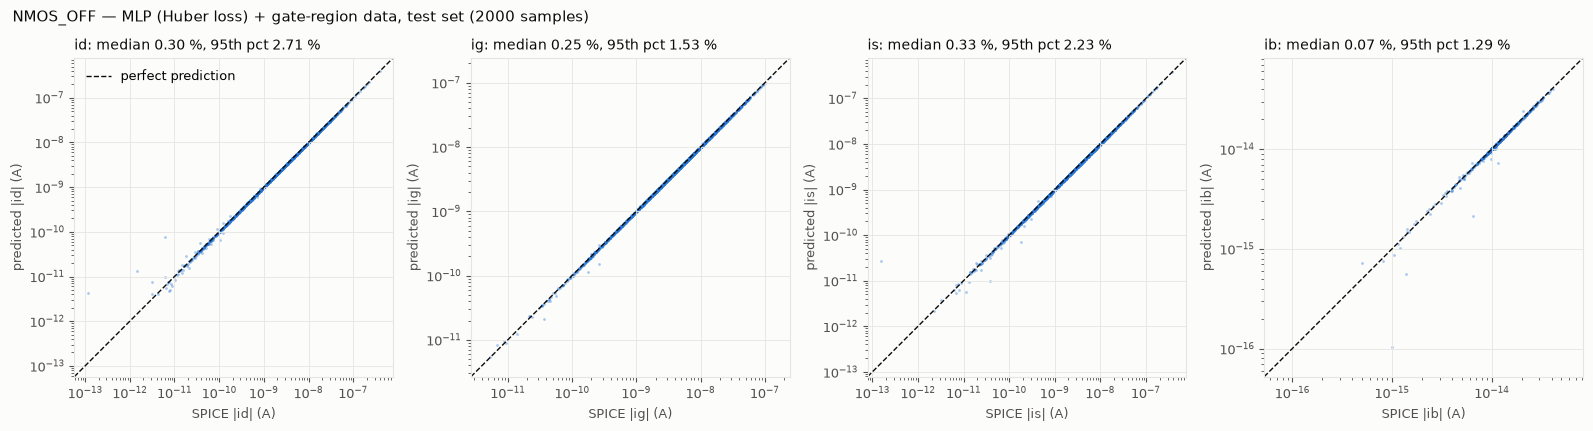

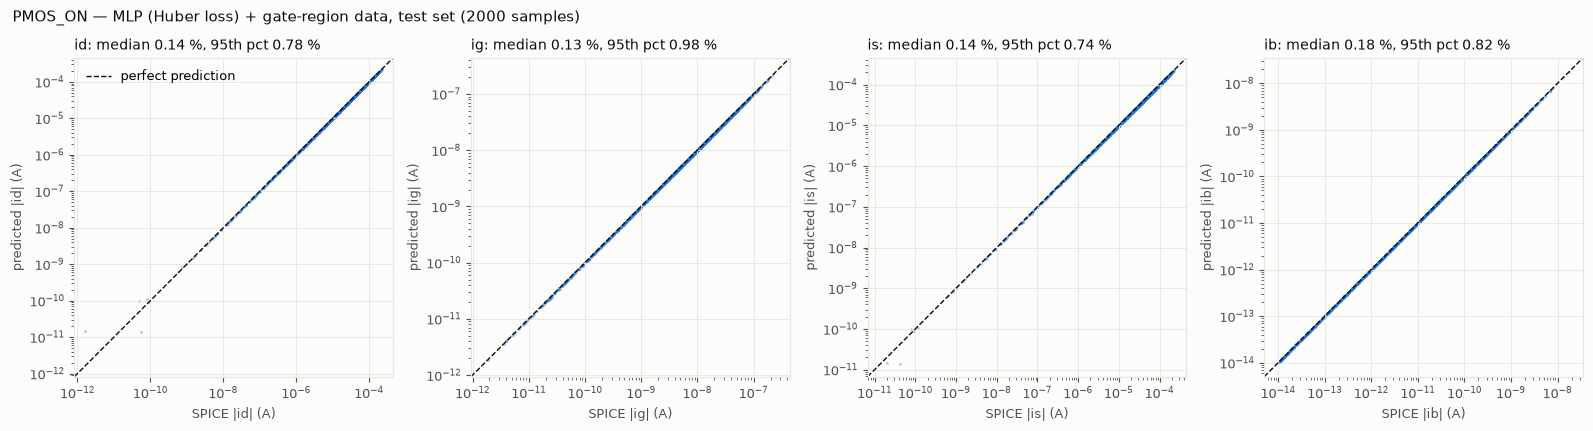

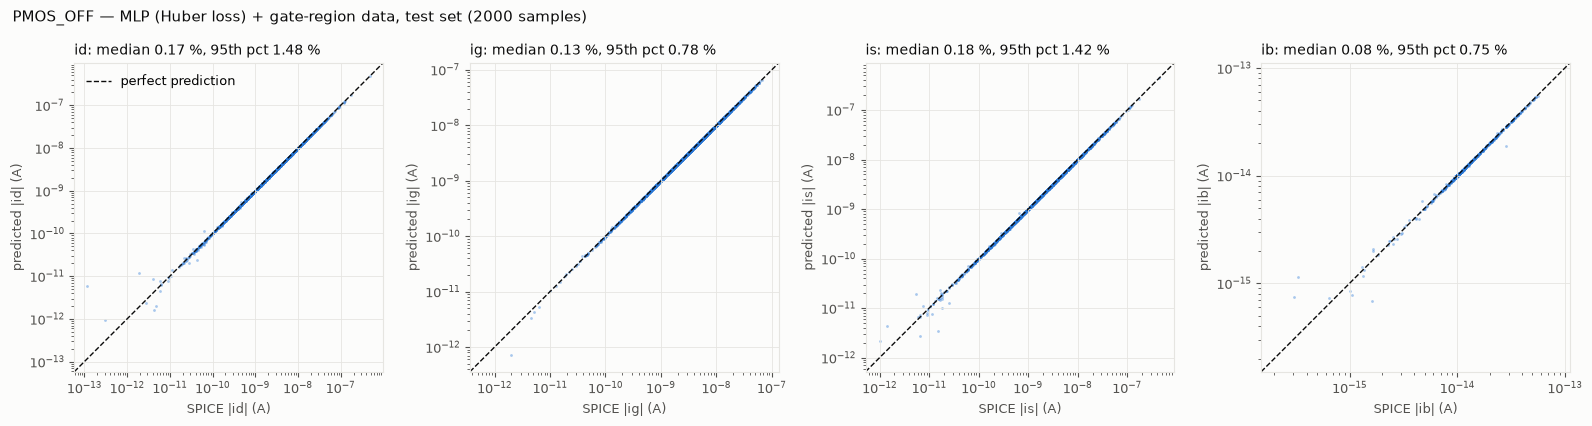

In [7]:
for case, (Y_true, Y_pred) in PRED.items():
    t = test_tables[case]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    for k, (ax, c) in enumerate(zip(axes, OUTPUT_COLS)):
        x, y = 10 ** Y_true[:, k], 10 ** Y_pred[:, k]
        lo, hi = min(x.min(), y.min()) / 2, max(x.max(), y.max()) * 2
        ax.plot([lo, hi], [lo, hi], color=INK, lw=1, ls="--", label="perfect prediction")
        ax.scatter(x, y, s=4, alpha=0.4, color=BLUE, linewidths=0, rasterized=True)
        ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), aspect="equal",
               xlabel=f"SPICE |{c}| (A)", ylabel=f"predicted |{c}| (A)")
        ax.set_title(f"{c}: median {t.loc[c, 'median err %']:.2f} %, 95th pct {t.loc[c, '95th pct err %']:.2f} %", loc="left")
    axes[0].legend(loc="upper left")
    fig.suptitle(f"{case} — {models[case].info['model']}, test set ({len(Y_true)} samples)",
                 color=INK, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"parity_{case}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 5. Where the mean error comes from

The mean of a % error is easily dominated by a few rows: if the SPICE current of one sample is tiny, a small error in
its log becomes a huge % error. This section measures how much of each mean error comes from the **5 worst rows** (0.25 %
of the 2,000 test rows) and what those rows look like. It is a diagnosis only: nothing here is used to select or change a model.

- `|I| / largest current` is the size of one terminal current relative to the largest current of the same sample.
  A value near 0 means the current is almost cancelled by the others (e.g. the drain channel leakage and the gate / junction
  leakage flowing in opposite directions).
- `SPICE Kirchhoff residual / |I|` compares the SPICE data's own inconsistency, |Id + Ig + Is + Ib|, with the target
  current. When it approaches 1, the target is at the numerical precision of the SPICE solution (the data check shows the
  residual is about 1e-6 of the largest current), so no model can predict it to better than that.


In [8]:
# 5a. share of each mean error that comes from the 5 worst test rows
rows = []
for case, (Y_true, Y_pred) in PRED.items():
    err = np.abs(10 ** (Y_pred - Y_true) - 1) * 100                         # % error, shape (n, 4)
    for k, c in enumerate(OUTPUT_COLS):
        e = np.sort(err[:, k])[::-1]
        rows.append({"case": case, "current": c, "mean err %": e.mean(), "median err %": np.median(e),
                     "rows with err > 100 %": int((e > 100).sum()),
                     "mean err % without 5 worst rows": e[5:].mean(),
                     "share of mean from 5 worst rows": e[:5].sum() / e.sum()})
concentration = pd.DataFrame(rows).set_index(["case", "current"])
concentration.to_csv(RESULTS_DIR / "error_concentration.csv")
concentration


mean err %  median err %  rows with err > 100 %  \
case     current                                                    
NMOS_ON  id            0.737          0.14                      2   
         ig            0.397          0.14                      0   
         is            0.817         0.139                      2   
         ib             0.24         0.162                      0   
NMOS_OFF id             3.81         0.304                      4   
         ig            0.537         0.249                      0   
         is             9.46          0.33                      1   
         ib            0.485        0.0699                      0   
PMOS_ON  id            0.745         0.144                      2   
         ig            0.272         0.131                      0   
         is            0.302         0.142                      0   
         ib            0.275         0.179                      0   
PMOS_OFF id             3.48         0.171                      4   
         ig            0.314         0.135                      0   
         is            0.907          0.18                      3   
         ib            0.518        0.0761                      2   

                  mean err % without 5 worst rows  \
case     current                                    
NMOS_ON  id                                 0.292   
         ig                                 0.314   
         is                                 0.299   
         ib                                 0.236   
NMOS_OFF id                                 0.907   
         ig                                  0.46   
         is                                 0.766   
         ib                                 0.338   
PMOS_ON  id                                 0.244   
         ig                                 0.258   
         is                                 0.234   
         ib                                 0.268   
PMOS_OFF id                                 0.601   
         ig                                 0.246   
         is                                 0.551   
         ib                                 0.263   

                  share of mean from 5 worst rows  
case     current                                   
NMOS_ON  id                                 0.605  
         ig                                 0.212  
         is                                 0.635  
         ib                                0.0212  
NMOS_OFF id                                 0.762  
         ig                                 0.145  
         is                                 0.919  
         ib                                 0.305  
PMOS_ON  id                                 0.673  
         ig                                0.0547  
         is                                  0.23  
         ib                                  0.03  
PMOS_OFF id                                 0.828  
         ig                                 0.219  
         is                                 0.394  
         ib                                 0.494

In [9]:
# 5b. error against how far id / is are cancelled by the other currents
#     held-out rows = validation + test (4,000 rows, never trained on); only id and is, the terminals whose signed
#     current can change sign (ig and ib keep one sign and are naturally small next to the channel current)
BINS   = [0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0001]
LABELS = ["< 0.01 %", "0.01 - 0.1 %", "0.1 - 1 %", "1 - 10 %", "10 - 100 %"]
tables, worst = {}, []
for case, m in models.items():
    df = pd.read_csv(DATA_DIR / m.info["dataset"])
    _, idx_val, idx_test = split_indices(len(df), m.info.get("split_seed", m.info["seed"]))
    idx = np.concatenate([idx_val, idx_test])
    I = df[OUTPUT_COLS].iloc[idx]
    ratio = I.abs().div(I.abs().max(axis=1), axis=0).values[:, [0, 2]]       # |I_k| / largest current of the sample
    err = np.abs(10 ** (m.predict_log(df.iloc[idx]) - np.log10(I.abs().values)) - 1)[:, [0, 2]] * 100
    bins = pd.cut(pd.Series(ratio.ravel()), BINS, labels=LABELS)
    tables[case] = (pd.DataFrame({"err": err.ravel(), "bin": bins})
                    .groupby("bin", observed=True)["err"].agg(["count", "mean", "median", "max"]))

    # the 3 worst (row, current) pairs of the test set, with the SPICE data's own Kirchhoff residual
    It = df[OUTPUT_COLS].iloc[idx_test]
    Y_true, Y_pred = PRED[case]
    e_test = np.abs(10 ** (Y_pred - Y_true) - 1) * 100
    for flat in np.argsort(e_test.ravel())[::-1][:3]:
        r, k = divmod(flat, len(OUTPUT_COLS))
        row = It.iloc[r]
        worst.append({"case": case, "row in dataset": int(idx_test[r]), "current": OUTPUT_COLS[k],
                      "|I| (A)": abs(row.iloc[k]), "largest current (A)": row.abs().max(),
                      "|I| / largest": abs(row.iloc[k]) / row.abs().max(),
                      "SPICE Kirchhoff residual / |I|": abs(row.sum()) / abs(row.iloc[k]), "error %": e_test[r, k]})
display(pd.concat(tables, names=["case", "|I| / largest current"]))
pd.DataFrame(worst).set_index(["case", "row in dataset"])


count     mean   median      max
case     |I| / largest current                                  
NMOS_ON  1 - 10 %                   2      756      756 1.16e+03
         10 - 100 %              7998    0.563    0.141      569
NMOS_OFF < 0.01 %                   3  1.5e+04 1.72e+04 2.41e+04
         0.01 - 0.1 %               7      340      130 1.05e+03
         0.1 - 1 %                 68     31.4     5.68      752
         1 - 10 %                 859     4.55    0.565 1.15e+03
         10 - 100 %              7063     0.58    0.285     61.2
PMOS_ON  1 - 10 %                   1      770      770      770
         10 - 100 %              7999    0.332    0.141      294
PMOS_OFF < 0.01 %                   1 4.85e+03 4.85e+03 4.85e+03
         0.01 - 0.1 %              12      351      178 1.22e+03
         0.1 - 1 %                 51     34.9     14.1      259
         1 - 10 %                 637     1.78     0.43     82.7
         10 - 100 %              7299    0.443    0.167      335

current  |I| (A)  largest current (A)  |I| / largest  \
case     row in dataset                                                        
NMOS_ON  128                 id 1.36e-12             9.31e-12          0.146   
         19570               is 1.75e-13             1.59e-12           0.11   
         15989               is 1.71e-12             1.21e-11          0.141   
NMOS_OFF 13855               is 1.57e-13             5.29e-09       2.97e-05   
         522                 id 1.14e-13             2.29e-09       4.99e-05   
         10269               id 5.98e-12             1.83e-10         0.0327   
PMOS_ON  7987                id 1.64e-12             2.18e-11         0.0752   
         14218               id 4.78e-11             8.06e-11          0.593   
         16053               id 5.56e-11             9.85e-11          0.565   
PMOS_OFF 11770               id 1.16e-13             1.47e-09       7.89e-05   
         595                 id 1.94e-12             8.82e-09        0.00022   
         14736               is 5.42e-12             2.98e-09        0.00182   

                         SPICE Kirchhoff residual / |I|  error %  
case     row in dataset                                           
NMOS_ON  128                                   4.33e-05      569  
         19570                                  0.00028      417  
         15989                                 0.000259      370  
NMOS_OFF 13855                                   0.0193 1.72e+04  
         522                                     0.0493 3.64e+03  
         10269                                 0.000112 1.15e+03  
PMOS_ON  7987                                  2.14e-05      770  
         14218                                 9.62e-07      109  
         16053                                  1.5e-06     75.7  
PMOS_OFF 11770                                   0.0551 4.85e+03  
         595                                    0.00167      505  
         14736                                 0.000474      259

**Reading the result** (final models: MLP with the Huber loss, also trained on gate-region rows)

- **A handful of rows decides the mean.** On the test set the 5 worst rows (0.25 % of the rows) account for 76 % of the
  NMOS_OFF mean error of `id` (3.8 % → 0.91 % without them) and 92 % of the mean error of `is` (9.5 % → 0.77 % without them):
  one single `is` row (dataset row 13855, error 1.7e4 %) contributes 8.6 points. For PMOS_OFF the same rows account for 83 %
  (`id`) and 39 % (`is`). Which terminal carries the outlier changes from set to set: on the validation set the NMOS_OFF outlier
  is in `id` (mean 14.6 %), on the test set in `is`.
- **The cause is current cancellation, and the error grows steadily with its depth** (table 5b, `id` and `is` of held-out rows).
  NMOS_OFF mean error is 0.58 % when the current is 10 – 100 % of the largest current of the sample, 4.6 % at 1 – 10 %
  (one row with 1.2e3 % error contributes 1.3 of these points), 31 % at 0.1 – 1 %, 340 % at 0.01 – 0.1 % and 1.5e4 % below 0.01 %
  (3 of 8,000 pairs). `id` and `is` of an OFF transistor are differences of two terms with opposite signs (channel leakage and
  gate / junction leakage), so the signed current crosses zero inside the sampled space. Near the crossing |I| → 0 and log|I|
  dives; a smooth network cannot follow that dip, and a prediction that is off by a factor of 2 in a 1e-13 A current is
  "100 % wrong" in a table of means.
- **The ON cases have no near-cancelled pairs** (NMOS_ON 2 and PMOS_ON 1 pair below 10 % of the largest current). Their few large
  errors (up to 1,160 %) sit at samples with vd ≈ vs (0.3 – 25 mV apart) close to the gate voltage, where the transistor barely
  conducts and all four currents are tiny (largest 1e-12 – 1e-10 A).
- **NMOS_OFF has deeper dips than PMOS_OFF:** 3 held-out pairs below 0.01 % (PMOS_OFF: 1), smallest |id| 2.9e-15 A (PMOS_OFF 4.7e-14 A),
  worst error 2.4e4 % (PMOS_OFF 4.9e3 %).
- **At the worst rows the SPICE data itself is uncertain at the percent level.** The data's own Kirchhoff residual is 1.9 % and 4.9 %
  of the two worst NMOS_OFF targets (table 5b, last column), while the model is off by thousands of %.
- **What to report:** the median and the 95th percentile describe typical-sample accuracy and are similar for all four cases
  (test median: NMOS_ON 0.15 %, NMOS_OFF 0.24 %, PMOS_ON 0.15 %, PMOS_OFF 0.14 %). The NMOS_OFF *mean* is not a reliable measure of
  typical accuracy because it depends on whether 1 – 5 rows near a zero crossing land in the evaluated set; that is why it also
  changes between the validation set (4.13 %) and the test set (3.57 %). No rows were removed: every row is a valid SPICE result.
  At gate level such a strongly cancelled current is tiny in amperes; Part B reaches 99.7 % mean accuracy.


## Summary

In [10]:
for case in CASES:
    if case not in test_tables:
        print(f"{case:9s} not available yet")
        continue
    a = test_tables[case].loc["average"]
    print(f"{case:9s} {models[case].info['model']:22s} test: median {a['median err %']:.2f} %   "
          f"95th pct {a['95th pct err %']:.2f} %   mean {a['mean err %']:.2f} %")

NMOS_ON   MLP (Huber loss) + gate-region data test: median 0.15 %   95th pct 0.82 %   mean 0.55 %
NMOS_OFF  MLP (Huber loss) + gate-region data test: median 0.24 %   95th pct 1.94 %   mean 3.57 %
PMOS_ON   MLP (Huber loss) + gate-region data test: median 0.15 %   95th pct 0.83 %   mean 0.40 %
PMOS_OFF  MLP (Huber loss) + gate-region data test: median 0.14 %   95th pct 1.11 %   mean 1.30 %
